<a href="https://colab.research.google.com/github/Bilal-data/superstore-sales-analysis/blob/main/superstore_sales_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!ls /content/drive/MyDrive | grep -i archive

archive.zip


In [ ]:
!unzip -o /content/drive/MyDrive/archive.zip -d /content/superstore
!ls -lh /content/superstore

Archive:  /content/drive/MyDrive/archive.zip
  inflating: /content/superstore/train.csv  
total 2.1M
-rw-r--r-- 1 root root 2.1M Sep 11  2020 train.csv


In [ ]:
import pandas as pd

sales = pd.read_csv("/content/superstore/train.csv")
print(sales.shape)
print(sales.columns.tolist())

(9800, 18)
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales']


In [ ]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   object 
 2   Order Date     9800 non-null   object 
 3   Ship Date      9800 non-null   object 
 4   Ship Mode      9800 non-null   object 
 5   Customer ID    9800 non-null   object 
 6   Customer Name  9800 non-null   object 
 7   Segment        9800 non-null   object 
 8   Country        9800 non-null   object 
 9   City           9800 non-null   object 
 10  State          9800 non-null   object 
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   object 
 13  Product ID     9800 non-null   object 
 14  Category       9800 non-null   object 
 15  Sub-Category   9800 non-null   object 
 16  Product Name   9800 non-null   object 
 17  Sales          9800 non-null   float64
dtypes: float

In [ ]:
sales[["Order ID", "Order Date", "Category", "Product Name", "Sales"]].head(5)

,Order ID,Order Date,Category,Product Name,Sales
0,CA-2017-152156,08/11/2017,Furniture,Bush Somerset Collection Bookcase,261.9600
1,CA-2017-152156,08/11/2017,Furniture,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,CA-2017-138688,12/06/2017,Office Supplies,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,US-2016-108966,11/10/2016,Furniture,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,US-2016-108966,11/10/2016,Office Supplies,Eldon Fold 'N Roll Cart System,22.3680


In [ ]:
sales["Order Date"] = pd.to_datetime(sales["Order Date"], dayfirst=True)
print(sales["Order Date"].min())
print(sales["Order Date"].max())

2015-01-03 00:00:00
2018-12-30 00:00:00


In [ ]:
sales["Year"] = sales["Order Date"].dt.year
sales.groupby("Year")["Sales"].sum().round(0)

,Sales
Year,
2015,479856.0
2016,459436.0
2017,600193.0
2018,722052.0


In [ ]:
sales.groupby("Category")["Sales"].sum().round(0).sort_values(ascending=False)

,Sales
Category,
Technology,827456.0
Furniture,728659.0
Office Supplies,705422.0


In [ ]:
sales["Category"].value_counts()

,count
Category,
Office Supplies,5909
Furniture,2078
Technology,1813


In [ ]:
sales.groupby("Category")["Sales"].agg(["count", "sum", "mean", "median"]).round(0)

,count,sum,mean,median
Category,,,,
Furniture,2078,728659.0,351.0,183.0
Office Supplies,5909,705422.0,119.0,27.0
Technology,1813,827456.0,456.0,168.0


In [ ]:
sales.nlargest(5, "Sales")[["Order Date", "Category", "Sub-Category", "Product Name", "Sales"]]

,Order Date,Category,Sub-Category,Product Name,Sales
2697,2015-03-18,Technology,Machines,Cisco TelePresence System EX90 Videoconferenci...,22638.480
6826,2017-10-02,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,17499.950
8153,2018-03-23,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,13999.960
2623,2018-10-22,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,11199.968
4190,2018-11-17,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,10499.970


In [ ]:
sales.groupby("Region")["Sales"].sum().round(0).sort_values(ascending=False)

,Sales
Region,
West,710220.0
East,669519.0
Central,492647.0
South,389151.0


In [ ]:
sales.groupby("Region")["Sales"].agg(["count", "mean", "median"]).round(0)

,count,mean,median
Region,,,
Central,2277,216.0,46.0
East,2785,240.0,55.0
South,1598,244.0,54.0
West,3140,226.0,61.0


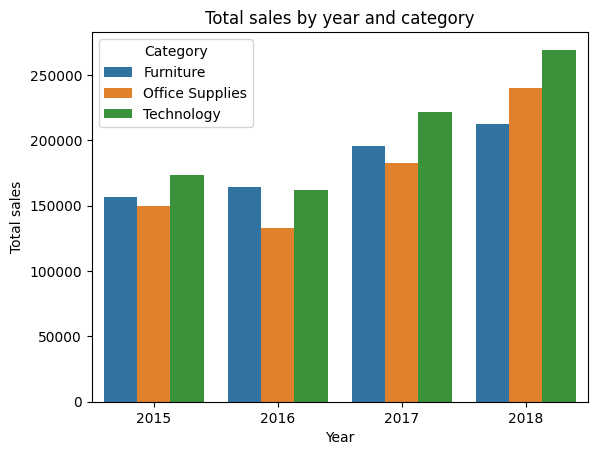

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.barplot(data=sales, x="Year", y="Sales", hue="Category",
            estimator="sum", errorbar=None)
plt.title("Total sales by year and category")
plt.ylabel("Total sales")
plt.show()

In [ ]:
pivot = sales.pivot_table(index="Year", columns="Category",
                          values="Sales", aggfunc="sum").round(0)
pivot

Category,Furniture,Office Supplies,Technology
Year,,,
2015,156478.0,149513.0,173866.0
2016,164054.0,133124.0,162258.0
2017,195813.0,182418.0,221962.0
2018,212314.0,240368.0,269371.0


## Findings (Superstore Sales, 9,800 line items, 2015-2018)

- **Data:** each row is one product line inside an order, not one order. The file has revenue (Sales) only: no profit, discount or quantity columns.
- **By year:** 479,856 (2015), 459,436 (2016), 600,193 (2017), 722,052 (2018). Sales dipped about 4% in 2016, then grew about 31% and 20%.
- **By category:** Technology 827,456 (36.6%), Furniture 728,659 (32.2%), Office Supplies 705,422 (31.2%).
- **Item prices are skewed:** Office Supplies has the most line items (5,909) but a median item of only 27 (mean 119). Technology's mean (456) is pulled up by a few huge sales: the top 5 rows are about 9.2% of Technology sales, and 4 of them are the same Canon copier.
- **By region:** West 710,220 (31.4%), East 669,519, Central 492,647, South 389,151 (17.2%). South has the fewest line items (1,598) but the highest mean per item (244).
- **Growth 2015 to 2018:** Office Supplies +61%, Technology +55%, Furniture +36%.

**Limitations:** revenue only, no profit; descriptive analysis with no statistical tests; I cannot tell why regions or categories differ (no customer, store or quantity data); Technology led in 3 of 4 years and Furniture was slightly ahead in 2016.

In [ ]:
print(sales["Order ID"].nunique())
print(sales["Customer ID"].nunique())

4922
793


In [ ]:
by_customer = sales.groupby("Customer ID")["Sales"].sum().sort_values(ascending=False)
print(by_customer.head(10).round(0))
print(by_customer.head(10).sum() / by_customer.sum() * 100)

Customer ID
SM-20320    25043.0
TC-20980    19052.0
RB-19360    15117.0
TA-21385    14596.0
AB-10105    14474.0
KL-16645    14175.0
SC-20095    14142.0
HL-15040    12873.0
SE-20110    12209.0
CC-12370    12129.0
Name: Sales, dtype: float64
6.8011791882672


In [ ]:
n = int(len(by_customer) * 0.2)
print(n)
print(by_customer.head(n).sum() / by_customer.sum() * 100)

158
48.29268676302923


## Customers

- 793 customers placed 4,922 orders: about 2 line items per order and about 6.2 orders per customer over 4 years.
- The top 10 customers (1.3% of customers) bring 6.8% of sales; the best single customer is about 1.1%.
- The top 20% of customers (158 of 793) bring 48.3% of sales: concentrated, but far from the 80/20 rule.
- **Limits:** customers are ranked by total revenue over 4 years, not by profit; I have no data on when each customer last ordered, so I cannot tell who is still active.